# Этап 3. Часть 2 — Предобработка данных и масштабирование

## Цель работы
На этом этапе сравниваются несколько методов масштабирования числового признака `Previous Scores`, а затем выполняется предобработка всех признаков с корректным разделением данных на обучающую и тестовую выборки.

**План работы:**
1. Загрузить подготовленный датасет и проверить его структуру.
2. Разделить данные на train и test в соотношении 80/20.
3. Сравнить StandardScaler, MinMaxScaler и RobustScaler на признаке `Previous Scores`.
4. Визуализировать распределение признака до и после преобразований.
5. Выбрать методы предобработки для всех признаков.
6. Обучить преобразователи только на train и применить их к test.

## 1. Импорт библиотек

Используем pandas и numpy для работы с данными, matplotlib и seaborn для визуализации, а также инструменты scikit-learn для разделения выборки и предобработки признаков.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")

## 2. Загрузка и первичная проверка данных

Для работы используется очищенный датасет `Student_Performance_cleaned.csv`, полученный на предыдущем этапе проекта.

Если файл уже загружен в среду (например, Google Colab), укажите путь к нему в `DATA_PATH`. Если файл отсутствует, код предложит загрузить его.

In [2]:
from pathlib import Path

DATA_PATH = "/content/Student_Performance_cleaned.csv"

if not Path(DATA_PATH).exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        if not uploaded:
            raise FileNotFoundError("Файл не был загружен.")
        DATA_PATH = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(
            "Не найден Student_Performance_cleaned.csv. "
            "Поместите CSV рядом с ноутбуком или укажите корректный DATA_PATH."
        )

df = pd.read_csv(DATA_PATH)

print("Размер датасета:", df.shape)
display(df.head())

Размер датасета: (9873, 6)


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,1,9,1,91.0
1,4,82,0,4,2,65.0
2,8,51,1,7,2,45.0
3,5,52,1,5,2,36.0
4,7,75,0,8,5,66.0


In [3]:
print("Типы данных и информация о столбцах:")
df.info()

print("\nКоличество пропусков:")
display(df.isna().sum())

print("\nОписательная статистика числовых признаков:")
display(df.describe())

Типы данных и информация о столбцах:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9873 entries, 0 to 9872
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     9873 non-null   int64  
 1   Previous Scores                   9873 non-null   int64  
 2   Extracurricular Activities        9873 non-null   int64  
 3   Sleep Hours                       9873 non-null   int64  
 4   Sample Question Papers Practiced  9873 non-null   int64  
 5   Performance Index                 9873 non-null   float64
dtypes: float64(1), int64(5)
memory usage: 462.9 KB

Количество пропусков:


,0
Hours Studied,0
Previous Scores,0
Extracurricular Activities,0
Sleep Hours,0
Sample Question Papers Practiced,0
Performance Index,0



Описательная статистика числовых признаков:


,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,9873.000000,9873.000000,9873.000000,9873.000000,9873.000000,9873.000000
mean,4.992100,69.441102,0.494986,6.531652,4.583004,55.216651
std,2.589081,17.325601,0.500000,1.697683,2.867202,19.208570
min,1.000000,40.000000,0.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,0.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,0.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,1.000000,8.000000,7.000000,70.000000
max,9.000000,99.000000,1.000000,9.000000,9.000000,100.000000


Перед дальнейшей обработкой проверяем, что в таблице присутствуют ожидаемые столбцы, а числовые признаки действительно имеют числовой тип. Целевая переменная `Performance Index` не включается в масштабирование признаков.

In [4]:
expected_columns = [
    "Hours Studied",
    "Previous Scores",
    "Extracurricular Activities",
    "Sleep Hours",
    "Sample Question Papers Practiced",
    "Performance Index"
]

missing_columns = [col for col in expected_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"В датасете отсутствуют столбцы: {missing_columns}")

if df[expected_columns].isna().any().any():
    raise ValueError(
        "В данных обнаружены пропуски. "
        "Их необходимо обработать до масштабирования."
    )

numeric_columns = [
    "Hours Studied",
    "Previous Scores",
    "Sleep Hours",
    "Sample Question Papers Practiced",
    "Performance Index"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="raise")

print("Проверка структуры завершена.")

Проверка структуры завершена.


## 3. Разделение данных на обучающую и тестовую выборки

Разделяем датасет в соотношении 80/20. `Performance Index` — целевая переменная, остальные столбцы — признаки.

Разделение выполняется **до обучения масштабировщиков**. Это важно, чтобы информация из тестовой выборки не участвовала в настройке преобразований и не возникала утечка данных (data leakage).

In [5]:
X = df.drop(columns=["Performance Index"])
y = df["Performance Index"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Размер X_train:", X_train.shape)
print("Размер X_test:", X_test.shape)
print("Размер y_train:", y_train.shape)
print("Размер y_test:", y_test.shape)

Размер X_train: (7898, 5)
Размер X_test: (1975, 5)
Размер y_train: (7898,)
Размер y_test: (1975,)


## 4. Сравнение методов масштабирования признака Previous Scores

Для сравнения выбран признак `Previous Scores` (предыдущие баллы). Он является числовым и имеет более широкий диапазон значений, чем некоторые другие признаки датасета.

Рассмотрим три метода:

- **StandardScaler** — вычитает среднее и делит на стандартное отклонение. После преобразования обучающей выборки среднее будет близко к 0, а стандартное отклонение — к 1.
- **MinMaxScaler** — линейно преобразует значения обучающей выборки в диапазон от 0 до 1.
- **RobustScaler** — использует медиану и межквартильный размах, поэтому менее чувствителен к выбросам.

Каждый преобразователь обучается только на `X_train`, после чего тем же преобразованием обрабатывается `X_test`.

In [6]:
feature = "Previous Scores"

scalers = {
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler()
}

scaled_train_results = {}
scaled_test_results = {}

for name, scaler in scalers.items():
    train_values = scaler.fit_transform(X_train[[feature]]).ravel()
    test_values = scaler.transform(X_test[[feature]]).ravel()

    scaled_train_results[name] = train_values
    scaled_test_results[name] = test_values

print("Сравнение статистик обучающей выборки после масштабирования:")
comparison = []

for name, values in scaled_train_results.items():
    comparison.append({
        "Метод": name,
        "Среднее": np.mean(values),
        "Медиана": np.median(values),
        "Стандартное отклонение": np.std(values),
        "Минимум": np.min(values),
        "Максимум": np.max(values)
    })

display(pd.DataFrame(comparison).round(3))

Сравнение статистик обучающей выборки после масштабирования:


,Метод,Среднее,Медиана,Стандартное отклонение,Минимум,Максимум
0,StandardScaler,-0.000,-0.019,1.000,-1.695,1.715
1,MinMaxScaler,0.497,0.492,0.293,0.000,1.000
2,RobustScaler,0.011,0.000,0.558,-0.935,0.968


## 5. Визуализация распределения до и после масштабирования

На графиках показано распределение `Previous Scores` в обучающей выборке до преобразования и после применения каждого из трёх методов. Сравнение проводится на одной и той же части данных, чтобы различия были связаны именно с масштабированием.

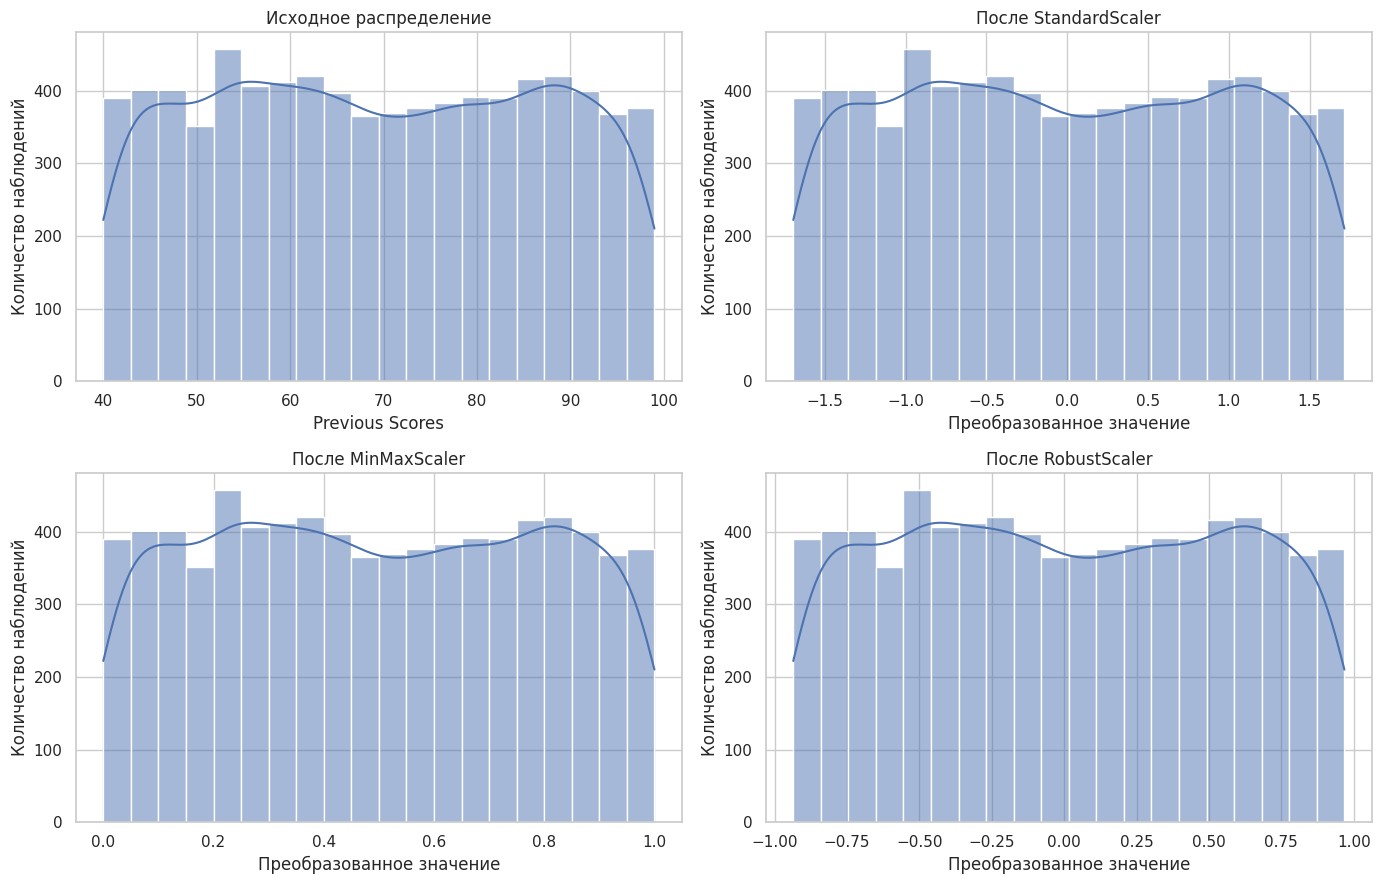

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(
    X_train[feature],
    bins=20,
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Исходное распределение")
axes[0, 0].set_xlabel(feature)
axes[0, 0].set_ylabel("Количество наблюдений")

plot_positions = [
    (axes[0, 1], "StandardScaler"),
    (axes[1, 0], "MinMaxScaler"),
    (axes[1, 1], "RobustScaler")
]

for ax, method_name in plot_positions:
    sns.histplot(
        scaled_train_results[method_name],
        bins=20,
        kde=True,
        ax=ax
    )
    ax.set_title(f"После {method_name}")
    ax.set_xlabel("Преобразованное значение")
    ax.set_ylabel("Количество наблюдений")

plt.tight_layout()
plt.show()

### Сравнение результатов

По результатам таблицы и графиков необходимо оценить, как изменились масштаб и положение распределения:

- StandardScaler центрирует значения относительно среднего и выражает их в единицах стандартного отклонения.
- MinMaxScaler сохраняет форму распределения, но переводит значения обучающей выборки в диапазон [0, 1].
- RobustScaler центрирует значения относительно медианы и масштабирует их по межквартильному размаху.

Масштабирование само по себе не делает распределение нормальным и не устраняет выбросы. Оно меняет шкалу признака.

**Вывод о наиболее подходящем методе:** выбор следует обосновать по полученным графикам и статистикам. Если в признаке нет выраженных выбросов и требуется центрирование относительно среднего, можно использовать StandardScaler. Если важен фиксированный диапазон [0, 1], подходит MinMaxScaler. Если присутствуют заметные выбросы, предпочтительнее RobustScaler. Окончательный выбор для этого датасета нужно сделать после просмотра результатов выполнения ячеек.

## 6. Предобработка всех признаков

Для остальных признаков применим следующие преобразования:

- числовые признаки (`Hours Studied`, `Previous Scores`, `Sleep Hours`, `Sample Question Papers Practiced`) — `StandardScaler`;
- категориальный признак `Extracurricular Activities` — `OneHotEncoder`.

`Performance Index` остаётся целевой переменной и не включается в `ColumnTransformer`.

Используем `ColumnTransformer`, чтобы объединить обработку числовых и категориальных столбцов. Преобразователь обучается на `X_train`, а к `X_test` применяется только `transform`.

In [8]:
numeric_features = [
    "Hours Studied",
    "Previous Scores",
    "Sleep Hours",
    "Sample Question Papers Practiced"
]

categorical_features = [
    "Extracurricular Activities"
]

# Проверяем значения категориального признака
print("Уникальные категории:")
display(X_train[categorical_features].nunique())
display(X_train["Extracurricular Activities"].value_counts(dropna=False))

Уникальные категории:


,0
Extracurricular Activities,2


,count
Extracurricular Activities,
0,3973
1,3925


In [9]:
numeric_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(
        drop="if_binary",
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

# Обучаем преобразователь только на обучающей выборке
X_train_processed = preprocessor.fit_transform(X_train)

# Тестовую выборку только преобразуем
X_test_processed = preprocessor.transform(X_test)

print("Размер обработанной X_train:", X_train_processed.shape)
print("Размер обработанной X_test:", X_test_processed.shape)

Размер обработанной X_train: (7898, 5)
Размер обработанной X_test: (1975, 5)


### Проверка результата предобработки

Проверяем, что размерности обучающей и тестовой выборок согласованы, а после преобразования не появились бесконечные или отсутствующие значения.

In [10]:
# Преобразуем в плотный массив только для удобной проверки и просмотра
X_train_array = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else np.asarray(X_train_processed)
)

X_test_array = (
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else np.asarray(X_test_processed)
)

print("Есть ли NaN в train:", np.isnan(X_train_array).any())
print("Есть ли NaN в test:", np.isnan(X_test_array).any())
print("Есть ли бесконечные значения в train:", np.isinf(X_train_array).any())
print("Есть ли бесконечные значения в test:", np.isinf(X_test_array).any())

assert X_train_array.shape[1] == X_test_array.shape[1]
assert not np.isnan(X_train_array).any()
assert not np.isnan(X_test_array).any()
assert not np.isinf(X_train_array).any()
assert not np.isinf(X_test_array).any()

print("Проверки пройдены: train и test обработаны согласованно.")

Есть ли NaN в train: False
Есть ли NaN в test: False
Есть ли бесконечные значения в train: False
Есть ли бесконечные значения в test: False
Проверки пройдены: train и test обработаны согласованно.


## 7. Итоговый вывод

В ходе предобработки были сравнены три метода масштабирования признака `Previous Scores`: StandardScaler, MinMaxScaler и RobustScaler. Каждый метод был обучен на обучающей выборке, а затем применён к тестовой, что позволило избежать утечки данных.

Для полной предобработки датасета числовые признаки были масштабированы с помощью StandardScaler, а категориальный признак `Extracurricular Activities` преобразован методом OneHotEncoder. Целевая переменная `Performance Index` была сохранена отдельно и не масштабировалась.

Таким образом, данные подготовлены к дальнейшему построению модели машинного обучения. Вывод о том, какой из трёх методов лучше подходит именно для `Previous Scores`, необходимо сформулировать по фактическим графикам и статистикам после запуска ноутбука.